# Thử nghiệm dự báo độ biến động bằng LSTM

Sổ tay này huấn luyện mô hình LSTM trên chuỗi đặc trưng lịch sử để dự báo độ lệch chuẩn mẫu của lợi suất thực tế trong 5 phiên giao dịch tiếp theo (`t+1` đến `t+5`). Dữ liệu và các phần chia xác thực theo thời gian được tạo bằng quy trình chung của dự án. Bộ chuẩn hóa chỉ được khớp trên dữ liệu huấn luyện; phần xác thực dùng để chọn số lượt lặp huấn luyện; tập kiểm tra cuối chỉ được đánh giá một lần.

Chạy sổ tay từ thư mục gốc dự án hoặc từ `notebooks/`.

In [7]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.pipeline.dataset import prepare_dataset, valid_history
from src.models.lstm_model import LSTMModel
from src.evaluation.regression import regression_metrics

config = load_config(ROOT / "config.yaml")
ticker = config["data"].get("ticker", "ACB")
dataset = prepare_dataset(ticker, config)
history = valid_history(dataset)
sequence_length = int(config["data"]["sequence_length"])
base_params = dict(config["models"]["lstm"])

print(f"Mã cổ phiếu: {ticker} | mục tiêu: {dataset.target} | kỳ hạn: {dataset.horizon} phiên")
print(f"Độ dài chuỗi đầu vào: {sequence_length} phiên")
print(f"Tập huấn luyện cuối: {dataset.train.date.min().date()} -> {dataset.train.date.max().date()} | số mẫu={len(dataset.train)}")
for i, (_, validation) in enumerate(dataset.validation_folds, start=1):
    print(f"Phần xác thực {i}: {validation.date.min().date()} -> {validation.date.max().date()} | số mẫu={len(validation)}")
print(f"Tập kiểm tra: {dataset.test.date.min().date()} -> {dataset.test.date.max().date()} | số mẫu={len(dataset.test)}")

Mã cổ phiếu: ACB | mục tiêu: target_volatility_5d | kỳ hạn: 5 phiên
Độ dài chuỗi đầu vào: 20 phiên
Tập huấn luyện cuối: 2018-12-28 -> 2025-08-01 | số mẫu=1639
Phần xác thực 1: 2023-02-02 -> 2023-07-31 | số mẫu=125
Phần xác thực 2: 2023-08-01 -> 2024-01-25 | số mẫu=125
Phần xác thực 3: 2024-01-26 -> 2024-07-31 | số mẫu=125
Phần xác thực 4: 2024-08-01 -> 2025-02-03 | số mẫu=125
Phần xác thực 5: 2025-02-04 -> 2025-08-01 | số mẫu=125
Tập kiểm tra: 2025-08-11 -> 2026-10-12 | số mẫu=291


## Chọn siêu tham số bằng các phần xác thực

Các cấu hình khảo sát thay đổi số nơ-ron lớp ẩn và tốc độ học. Để thời gian chạy hợp lý, mỗi cấu hình được huấn luyện tối đa 8 lượt lặp. Dùng kết quả để so sánh cấu hình. Mô hình cuối dùng số lượt lặp tối đa trong `config.yaml` và dừng sớm dựa trên kết quả xác thực. Có thể sửa danh sách `candidates` để khảo sát thêm.

In [8]:
from itertools import product

sweep_epochs = min(int(base_params.get("epochs", 25)), 8)
candidates = [
    {**base_params, "hidden_size": hidden, "learning_rate": rate, "weight_decay": decay,
     "epochs": sweep_epochs, "patience": min(int(base_params.get("patience", 5)), 2)}
    for hidden, rate, decay in product([16, 32], [0.001, 0.003], [0.0001])
]

def evaluate_lstm_params(params):
    fold_rows = []
    for fold_train, validation in dataset.validation_folds:
        candidate = LSTMModel(
            dataset.features, dataset.target, dataset.horizon, sequence_length,
            params=params, seed=config["seed"],
        ).fit(fold_train, validation, history)
        prediction = candidate.predict(history, validation["date"])
        truth = validation[["date", dataset.target]].rename(columns={dataset.target: "actual_volatility"})
        joined = truth.merge(prediction, on="date", validate="one_to_one")
        fold_rows.append(regression_metrics(joined["actual_volatility"], joined["predicted_volatility"]))
    return {
        "params": params,
        "validation_rmse": float(np.mean([row["rmse"] for row in fold_rows])),
        "validation_mae": float(np.mean([row["mae"] for row in fold_rows])),
        "fold_metrics": fold_rows,
    }

results = [evaluate_lstm_params(params) for params in candidates]
summary = pd.DataFrame([
    {"Số nơ-ron lớp ẩn": row["params"]["hidden_size"],
     "Tốc độ học": row["params"]["learning_rate"],
     "Hệ số điều chuẩn": row["params"]["weight_decay"],
     "RMSE xác thực": row["validation_rmse"],
     "MAE xác thực": row["validation_mae"]}
    for row in results
]).sort_values("RMSE xác thực").reset_index(drop=True)
display(summary)
best_params = min(results, key=lambda row: row["validation_rmse"])["params"]
print("Cấu hình tốt nhất:", {
    "Số nơ-ron lớp ẩn": best_params["hidden_size"],
    "Tốc độ học": best_params["learning_rate"],
    "Hệ số điều chuẩn": best_params["weight_decay"],
})

,Số nơ-ron lớp ẩn,Tốc độ học,Hệ số điều chuẩn,RMSE xác thực,MAE xác thực
0,32,0.003,0.0001,0.639304,0.477365
1,16,0.003,0.0001,0.640954,0.482937
2,16,0.001,0.0001,0.643509,0.474264
3,32,0.001,0.0001,0.664326,0.503696


Cấu hình tốt nhất: {'Số nơ-ron lớp ẩn': 32, 'Tốc độ học': 0.003, 'Hệ số điều chuẩn': 0.0001}


## Huấn luyện mô hình cuối

Phần xác thực cuối cùng được dùng để chọn số lượt lặp phù hợp. Sau đó mô hình khớp lại bộ chuẩn hóa trên toàn bộ dữ liệu huấn luyện trước giai đoạn kiểm tra và huấn luyện lại mạng cuối. Mỗi chuỗi đầu vào chỉ chứa đặc trưng đã có tại ngày dự báo.

In [9]:
final_params = dict(best_params)
final_params.update(base_params)
# Giữ siêu tham số đã chọn bằng dữ liệu xác thực và dùng số lượt lặp trong cấu hình.
final_params["hidden_size"] = best_params["hidden_size"]
final_params["learning_rate"] = best_params["learning_rate"]
final_params["weight_decay"] = best_params["weight_decay"]
final_params["epochs"] = int(base_params.get("epochs", 25))
final_params["patience"] = int(base_params.get("patience", 5))

last_train, last_validation = dataset.validation_folds[-1]
model = LSTMModel(
    dataset.features, dataset.target, dataset.horizon, sequence_length,
    params=final_params, seed=config["seed"],
).fit(last_train, last_validation, history, final_training_frame=dataset.train)
print("Hàm mất mát trên phần xác thực tại lượt được chọn:", model.validation_loss)
print("Siêu tham số cuối:", {
    "Số nơ-ron lớp ẩn": final_params["hidden_size"],
    "Tốc độ học": final_params["learning_rate"],
    "Hệ số điều chuẩn": final_params["weight_decay"],
    "Số lượt lặp tối đa": final_params["epochs"],
    "Kích thước lô": final_params["batch_size"],
})

Hàm mất mát trên phần xác thực tại lượt được chọn: 1.1174497604370117
Siêu tham số cuối: {'Số nơ-ron lớp ẩn': 32, 'Tốc độ học': 0.003, 'Hệ số điều chuẩn': 0.0001, 'Số lượt lặp tối đa': 25, 'Kích thước lô': 32}


## Đánh giá trên tập kiểm tra độc lập

Dự báo được chặn dưới tại 0 vì độ biến động không âm. Các chỉ số dưới đây chỉ dùng tập kiểm tra cuối, sau khi đã chọn cấu hình bằng dữ liệu xác thực.

In [10]:
test_forecast = model.predict(history, dataset.test["date"])
actual = dataset.test[["date", dataset.target]].rename(columns={dataset.target: "actual_volatility"})
comparison = actual.merge(test_forecast, on="date", validate="one_to_one")
metrics = regression_metrics(comparison["actual_volatility"], comparison["predicted_volatility"])
print("Các chỉ số trên tập kiểm tra:", metrics)
display(comparison.rename(columns={
    "date": "Ngày",
    "actual_volatility": "Độ biến động thực tế",
    "predicted_volatility": "Độ biến động dự báo",
    "model": "Mô hình",
    "raw_prediction": "Dự báo thô",
}).head())

Các chỉ số trên tập kiểm tra: {'mae': 0.6138738672674778, 'rmse': 0.9384539305968945, 'r2': -0.12789657282687328, 'samples': 291}


,Ngày,Độ biến động thực tế,Mô hình,Độ biến động dự báo,Dự báo thô
0,2025-08-11,2.745265,lstm,1.122974,1.122974
1,2025-08-12,2.513354,lstm,1.123616,1.123616
2,2025-08-13,3.251424,lstm,1.102369,1.102369
3,2025-08-14,2.796236,lstm,1.315682,1.315682
4,2025-08-15,4.555686,lstm,1.307718,1.307718


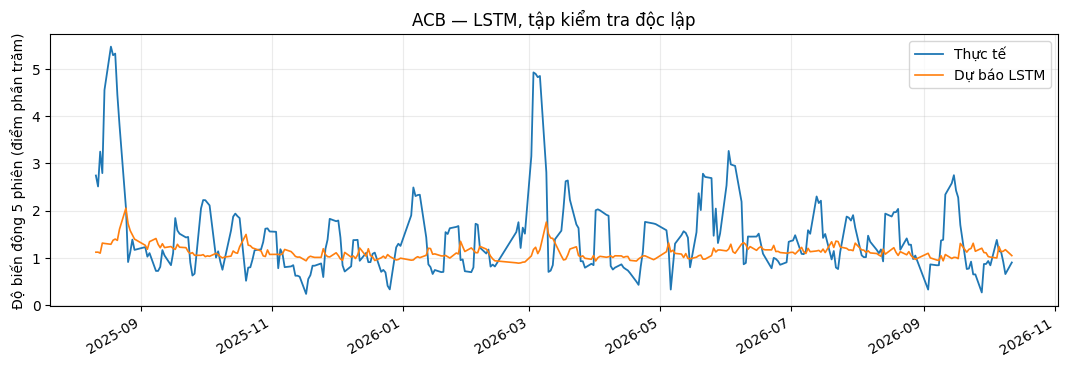

In [11]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(comparison["date"], comparison["actual_volatility"], label="Thực tế", linewidth=1.3)
ax.plot(comparison["date"], comparison["predicted_volatility"], label="Dự báo LSTM", linewidth=1.2)
ax.set(title=f"{ticker} — LSTM, tập kiểm tra độc lập",
       ylabel="Độ biến động 5 phiên (điểm phần trăm)")
ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); plt.show()

## Kiểm tra phần dư

Các biểu đồ cho thấy sai số có thay đổi theo độ biến động thực tế hay có độ lệch hệ thống hay không. Đây là phần mô tả, không dùng để điều chỉnh mô hình.

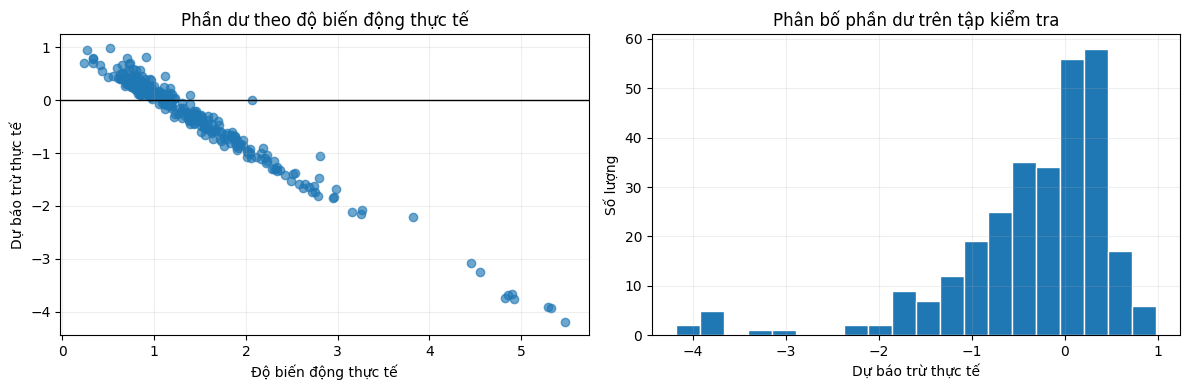

In [12]:
comparison["residual"] = comparison["predicted_volatility"] - comparison["actual_volatility"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(comparison["actual_volatility"], comparison["residual"], alpha=.65)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(xlabel="Độ biến động thực tế", ylabel="Dự báo trừ thực tế", title="Phần dư theo độ biến động thực tế")
axes[1].hist(comparison["residual"], bins=20, edgecolor="white")
axes[1].set(xlabel="Dự báo trừ thực tế", ylabel="Số lượng", title="Phân bố phần dư trên tập kiểm tra")
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## Tóm tắt

- Mục tiêu là độ lệch chuẩn mẫu của lợi suất thực tế trong các phiên `t+1` đến `t+5`.
- Bộ chuẩn hóa đặc trưng chỉ được khớp trên dữ liệu huấn luyện.
- Siêu tham số và số lượt lặp huấn luyện được chọn bằng các phần xác thực theo thời gian.
- Tập kiểm tra cuối chỉ dùng để báo cáo hiệu năng; kết quả không đảm bảo dự báo chính xác trong tương lai.